# k をどう決めるか — エルボー法とシルエット

**出典**　機械学習 4 分野の教科書 — 第 9 章 3-A クラスタリング ／ 08 実装：4 手法を同じデータで比較する

**このノートのパス**　`ml-code/09_clustering/02_choose_k.ipynb`

**このノートで確かめること**
**エルボー法は主観的、シルエットは最大値を選べる**という違いを、同じデータで並べて見る。

| 項目 | 内容 |
|---|---|
| 必要なパッケージ | `scikit-learn numpy matplotlib` |
| 実行時間の目安 | 約 15 秒 |
| 前提 | **このノート単体で完結する**（他のノートを先に実行する必要はない） |

In [2]:
# 未導入なら実行する（Colab など）
# !pip install -q scikit-learn numpy matplotlib

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

RS = 42
X_blob, _ = make_blobs(n_samples=400, centers=3, cluster_std=1.1, random_state=RS)
X_blob = StandardScaler().fit_transform(X_blob)

  File "<local-python>/lib/python3.10/site-packages/joblib/externals/loky/backend/context.py", line 264, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_darwin()
  File "<local-python>/lib/python3.10/site-packages/joblib/externals/loky/backend/context.py", line 420, in _count_physical_cores_darwin
    return int(cpu_info)


シルエット最大の k = 3  (score=0.830)


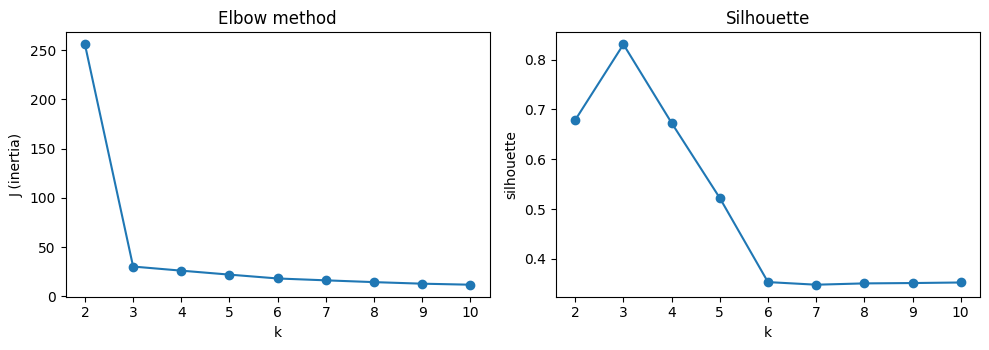

In [4]:
ks = range(2, 11)
inertias, sils = [], []

for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RS).fit(X_blob)
    inertias.append(km.inertia_)                       # これが目的関数 J
    sils.append(silhouette_score(X_blob, km.labels_))

best_k = list(ks)[int(np.argmax(sils))]
print(f"シルエット最大の k = {best_k}  (score={max(sils):.3f})")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(list(ks), inertias, "o-"); ax[0].set_xlabel("k"); ax[0].set_ylabel("J (inertia)")
ax[0].set_title("Elbow method")
ax[1].plot(list(ks), sils, "o-");     ax[1].set_xlabel("k"); ax[1].set_ylabel("silhouette")
ax[1].set_title("Silhouette")
plt.tight_layout(); plt.show()

## 読み取りどころ

- **`inertia_`（J）は k を増やすほど必ず下がる。**だから「最小を選ぶ」ことはできず、**折れ曲がり（肘）を目で探す**ことになる。ここが主観的。
- **シルエットは最大値を選べる**ので機械的に決まる。ただし前ノートのとおり「丸いクラスタ」を前提にした指標なので、万能ではない。
- ⚠️ **`n_init=10` を必ず付ける。**k-means は初期値依存で局所解に落ちる。1 回だけの試行で `inertia_` を比べると、k の違いではなく初期値の運を比べてしまう。

**正解の k が分かっているデータ（ここでは 3）で、両方の手法が 3 を指すかを確認しておく**のが、指標の癖を掴む早道である。